# Surat: How Built-up Surface Changed, 2000–2020
**Question 2: Individual Google Earth Engine Urban Analysis**
Rinsha Narayanan (HS25M110) | Urban Informatics and Spatial Analytics, IIT Tirupati

**Question:** How did total built-up surface in Surat change over two decades, and where are the major growth zones?

**Data:** GHSL Built-up Surface (`JRC/GHSL/P2023A/GHS_BUILT_S`, band `built_surface`). This is a 100 m grid with 5-year epochs (2000, 2005, 2010, 2015, 2020). Each cell gives the built-up area inside it in m², up to a maximum of 10,000 m².

**Boundary:** Surat Urban Local Body polygon (ULB code 802629) from the Swachh Bharat Mission ULB layer, released via `ramSeraph/indian_admin_boundaries` (CC0; attribution to datameet and the original government source).

**How the question is answered**
| Part | What it tells us |
|---|---|
| 3. City totals | How much built-up surface was added, and how fast in each 5-year interval |
| 4. Epoch maps | What the city looked like at each epoch (same colour scale) |
| 5. Footprint vs density | Did Surat grow outward (new built-up land) or fill in (denser existing areas)? |
| 6. When land became built-up | Which parts of the city were built-up by each epoch |
| 7. 1 km growth hotspots | The exact cells where most growth happened |
| 8. Distance from the core | Is growth at the centre or the edge? |
| 9. Direction (sectors) | Which side of the city grew most |
| 10. Dynamic outputs | GIF and an interactive time slider |
| 11. Key findings | All the numbers in one place |

One rule is used throughout. A 100 m cell counts as **built-up land** if at least 1,000 m² (10%) of it is built. This threshold `T` is only used for the footprint analysis in sections 5 and 6. All totals use the full built-up surface.

In [1]:
import io, requests
import ee, geemap
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from matplotlib.patches import Patch
from shapely.geometry import box, LineString
from PIL import Image, ImageDraw, ImageFont
from IPython.display import Image as Show
from pathlib import Path
import folium, branca.colormap as bcm
from folium.plugins import TimeSliderChoropleth

In [2]:
ee.Initialize(project="uisa-2026-gee")          

OUT = Path("outputs")                              
(OUT / "frames").mkdir(parents=True, exist_ok=True)
YEARS = [2000, 2005, 2010, 2015, 2020]             
T = 1000                                           # built-up land rule: ≥1,000 m² of a 100 m cell
UTM = 32643                                        # UTM zone 43N (metres), used for distances and areas

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## 1. City boundary
The Surat polygon was taken from `SBM_ULBs` using `ulbcode == 802629`. Filtering by name alone also returns Suratgarh and other towns in Surat district.

In [3]:
gdf = gpd.read_file("surat_ulb.geojson").to_crs(4326)     # single Surat polygon
fc = geemap.geopandas_to_ee(gdf[["ulbnm", "geometry"]])   # same polygon as an EE FeatureCollection
roi = fc.geometry()
city_km2 = gdf.to_crs(UTM).area.sum() / 1e6
print(f"Surat ULB area: {city_km2:.1f} km²")

Surat ULB area: 438.9 km²


## 2. Load GHSL built-up surface
Each epoch is a separate image (`.../GHS_BUILT_S/<year>`). The five epochs are stacked into one image with bands `b2000 … b2020`, so a single calculation covers all years. No cloud or seasonal filter is needed because GHSL epochs are already finished composite products.

In [4]:
ID = "JRC/GHSL/P2023A/GHS_BUILT_S"
built = {y: ee.Image(f"{ID}/{y}").select("built_surface") for y in YEARS}   # m² per 100 m cell
stack = ee.Image.cat([built[y].rename(f"b{y}") for y in YEARS])            # one band per epoch
PROJ = built[2000].projection()                                             # native 100 m GHSL grid

def km2(img):
    """Sum every band of an image (values in m²) inside Surat and return km²."""
    s = img.reduceRegion(ee.Reducer.sum(), roi, scale=100, crs=PROJ, maxPixels=1e9).getInfo()
    return {k: v / 1e6 for k, v in s.items()}

## 3. City totals and growth speed
- **built_km2:** total built-up surface inside Surat.
- **added_km2:** built-up surface added since the previous epoch.
- **annual_rate_pct:** average yearly growth in that 5-year interval. This shows whether growth sped up or slowed down.

In [5]:
surface = km2(stack)
df = pd.DataFrame({"year": YEARS, "built_km2": [surface[f"b{y}"] for y in YEARS]})
df["pct_of_city"] = df.built_km2 / city_km2 * 100
df["added_km2"] = df.built_km2.diff()
df["annual_rate_pct"] = ((df.built_km2 / df.built_km2.shift()) ** (1 / 5) - 1) * 100

start, end = df.built_km2.iloc[0], df.built_km2.iloc[-1]
total_inc, total_pct = end - start, (end / start - 1) * 100
cagr = ((end / start) ** (1 / 20) - 1) * 100       # average yearly growth over 20 years
print(f"2000: {start:.1f} km² → 2020: {end:.1f} km² | +{total_inc:.1f} km² ({total_pct:.0f}%) | {cagr:.1f}% per year")
df.round(2)

2000: 38.3 km² → 2020: 60.3 km² | +22.0 km² (57%) | 2.3% per year


,year,built_km2,pct_of_city,added_km2,annual_rate_pct
0,2000,38.35,8.74,NaN,NaN
1,2005,44.00,10.03,5.66,2.79
2,2010,51.19,11.66,7.18,3.07
3,2015,57.82,13.17,6.63,2.47
4,2020,60.30,13.74,2.48,0.84


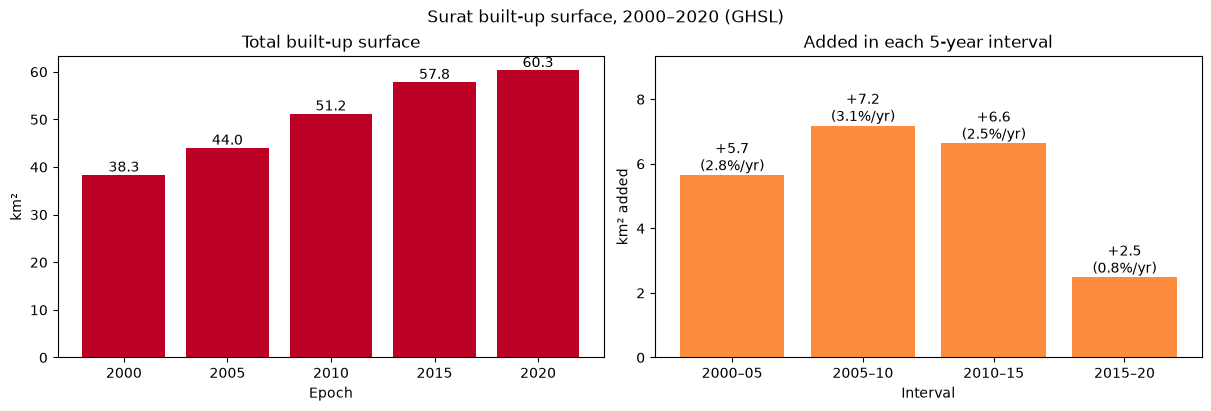

In [6]:
labels = [f"{a}–{str(b)[2:]}" for a, b in zip(YEARS[:-1], YEARS[1:])]   # e.g. 2000–05
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ax1.bar(df.year.astype(str), df.built_km2, color="#bd0026")
for i, v in enumerate(df.built_km2):
    ax1.text(i, v, f"{v:.1f}", ha="center", va="bottom")
ax1.set(title="Total built-up surface", xlabel="Epoch", ylabel="km²")
ax2.bar(labels, df.added_km2.iloc[1:], color="#fd8d3c")
for i, (v, r) in enumerate(zip(df.added_km2.iloc[1:], df.annual_rate_pct.iloc[1:])):
    ax2.text(i, v, f"+{v:.1f}\n({r:.1f}%/yr)", ha="center", va="bottom")
ax2.set(title="Added in each 5-year interval", xlabel="Interval", ylabel="km² added")
ax2.set_ylim(0, df.added_km2.max() * 1.3)
fig.suptitle("Surat built-up surface, 2000–2020 (GHSL)")
fig.savefig(OUT / "fig_totals.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Maps for each epoch
All five maps share one colour scale (0–8,000 m² built per 100 m cell), so they can be compared directly. Non-built cells sit on a grey city base, and the black line is the Surat boundary.

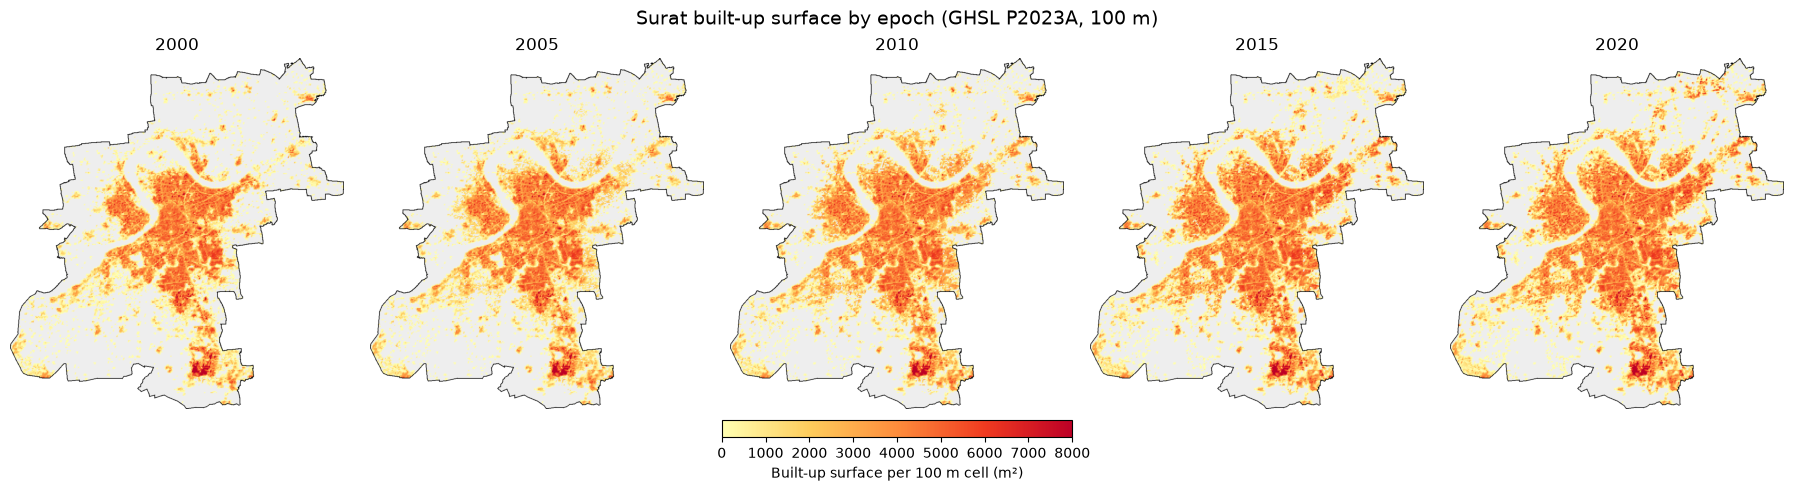

In [7]:
PAL = ["ffffb2", "fecc5c", "fd8d3c", "f03b20", "bd0026"]     # light → dark = low → high
VIS = {"min": 0, "max": 8000, "palette": PAL}
minx, miny, maxx, maxy = gdf.total_bounds
bbox = ee.Geometry.Rectangle([minx, miny, maxx, maxy], "EPSG:4326", False)
base = ee.Image.constant(1).clip(roi).visualize(min=0, max=1, palette=["eeeeee", "eeeeee"])
outline = ee.Image().byte().paint(fc, 1, 2).visualize(min=0, max=1, palette=["000000", "000000"])

def thumb(vis, dim=1000):
    """Download a visualised EE image over the city as an RGBA array."""
    url = vis.getThumbURL({"region": bbox, "dimensions": dim, "format": "png", "crs": "EPSG:3857"})
    return np.array(Image.open(io.BytesIO(requests.get(url, timeout=120).content)).convert("RGBA"))

def city_map(layer):
    """Put a visualised layer on the grey city base and add the boundary line."""
    return thumb(base.blend(layer.clip(roi)).blend(outline))

def colorbar(fig, ax, pal, vmin, vmax, label):
    """Add a horizontal colour bar that matches an EE palette."""
    sm = cm.ScalarMappable(norm=colors.Normalize(vmin, vmax), cmap=colors.LinearSegmentedColormap.from_list("p", ["#" + c for c in pal]))
    fig.colorbar(sm, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03, label=label)

frames = {y: city_map(built[y].updateMask(built[y].gt(0)).visualize(**VIS)) for y in YEARS}
for y in YEARS:
    Image.fromarray(frames[y]).save(OUT / "frames" / f"builtup_{y}.png")   # reused for slider/swipe on the webpage

fig, axes = plt.subplots(1, 5, figsize=(18, 4.8), layout="constrained")
for ax, y in zip(axes, YEARS):
    ax.imshow(frames[y]); ax.set_title(str(y)); ax.axis("off")
colorbar(fig, list(axes), PAL, 0, 8000, "Built-up surface per 100 m cell (m²)")
fig.suptitle("Surat built-up surface by epoch (GHSL P2023A, 100 m)", fontsize=14)
fig.savefig(OUT / "fig_epochs.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Footprint vs density: did Surat grow outward or fill in?
Two things can raise built-up surface:
- **Expansion:** land that was not built-up in 2000 becomes built-up (the footprint grows).
- **Densification:** cells that were already built-up in 2000 get more buildings.

`footprint_km2` is the area of built-up land (cells ≥ T). `density_pct` is how much of that footprint is actually covered by buildings. The 2000→2020 gain is then split by the type of cell it happened in.

In [8]:
foot = km2(stack.gte(T).multiply(10000))           # each built-up cell = 1 ha = 10,000 m²
df["footprint_km2"] = [foot[f"b{y}"] for y in YEARS]
df["new_footprint_km2"] = df.footprint_km2.diff()
df["density_pct"] = df.built_km2 / df.footprint_km2 * 100

diff = built[2020].subtract(built[2000])
old = built[2000].gte(T)                           # already built-up land in 2000
new = built[2000].lt(T).And(built[2020].gte(T))    # became built-up land by 2020
rest = built[2020].lt(T)                           # still below the rule in 2020
split = km2(ee.Image.cat([diff.updateMask(old).rename("densification"),   # EE band names: letters only
                          diff.updateMask(new).rename("expansion"),
                          diff.updateMask(rest).rename("scattered")]))
nice = {"densification": "Densification (built-up in 2000)", "expansion": "Expansion (new built-up land)",
        "scattered": "Scattered (still sparse in 2020)"}
growth = pd.Series({nice[k]: split[k] for k in nice}, name="gain_km2").to_frame()   # readable labels, fixed order
growth["share_pct"] = growth.gain_km2 / growth.gain_km2.sum() * 100
display(df[["year", "footprint_km2", "new_footprint_km2", "density_pct"]].round(2))
growth.round(2)

,year,footprint_km2,new_footprint_km2,density_pct
0,2000,103.87,NaN,36.92
1,2005,129.45,25.58,33.99
2,2010,146.42,16.97,34.96
3,2015,156.45,10.03,36.96
4,2020,163.88,7.42,36.80


,gain_km2,share_pct
Densification (built-up in 2000),4.83,22.01
Expansion (new built-up land),15.56,70.88
Scattered (still sparse in 2020),1.56,7.11


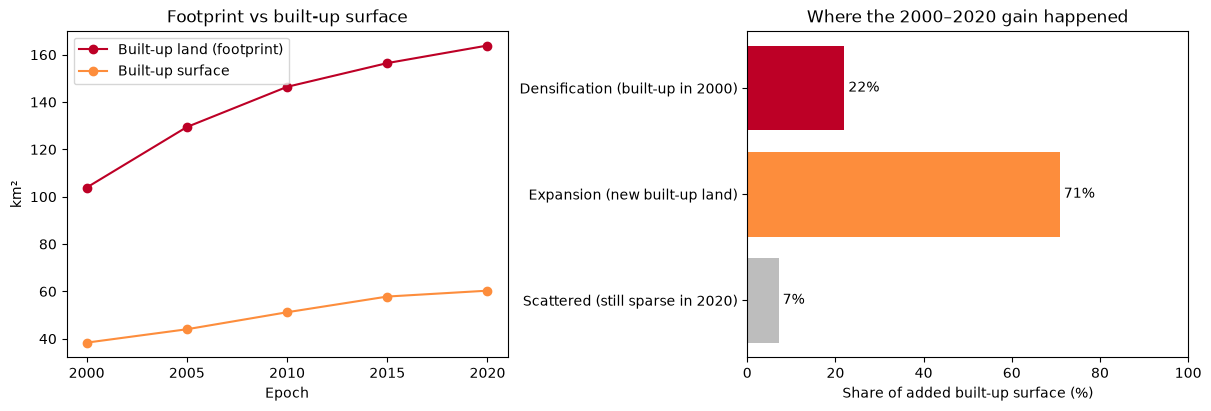

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ax1.plot(df.year, df.footprint_km2, "o-", color="#bd0026", label="Built-up land (footprint)")
ax1.plot(df.year, df.built_km2, "o-", color="#fd8d3c", label="Built-up surface")
ax1.set(title="Footprint vs built-up surface", xlabel="Epoch", ylabel="km²", xticks=YEARS); ax1.legend()
ax2.barh(growth.index[::-1], growth.share_pct[::-1], color=["#bdbdbd", "#fd8d3c", "#bd0026"])
for i, v in enumerate(growth.share_pct[::-1]):
    ax2.text(v, i, f" {v:.0f}%", va="center")
ax2.set(title="Where the 2000–2020 gain happened", xlabel="Share of added built-up surface (%)")
ax2.set_xlim(0, 100)
fig.savefig(OUT / "fig_footprint.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. When did each part of the city become built-up?
Each 100 m cell is coloured by the first epoch in which it crossed the built-up rule (T). Grey cells were already built-up in 2000, and the brighter colours show the newer additions. This makes the direction of growth easy to see.

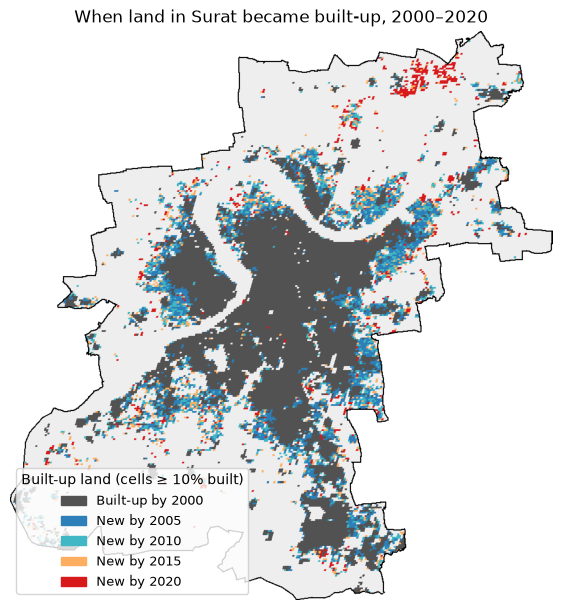

In [10]:
EPAL = ["525252", "2c7fb8", "41b6c4", "fdae61", "d7191c"]   # 2000 grey → 2020 red
first = ee.ImageCollection([built[y].gte(T).selfMask().multiply(y).toInt16().rename("first") for y in YEARS]).min()
when = city_map(first.visualize(min=2000, max=2020, palette=EPAL))

fig, ax = plt.subplots(figsize=(7, 7.5))
ax.imshow(when); ax.axis("off")
names = ["Built-up by 2000"] + [f"New by {y}" for y in YEARS[1:]]
ax.legend(handles=[Patch(color="#" + c, label=n) for c, n in zip(EPAL, names)], loc="lower left", fontsize=9, title="Built-up land (cells ≥ 10% built)")
ax.set_title("When land in Surat became built-up, 2000–2020")
fig.savefig(OUT / "fig_when_built.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Growth hotspots on a 1 km grid
The 100 m change map is detailed but noisy. The city is therefore cut into 1 km × 1 km cells (edge cells are clipped to the boundary), and the built-up surface of each epoch is summed in every cell. Values are in **hectares (ha)**, and a full 1 km cell is 100 ha. The **hotspots** are the top 10% of cells by growth.

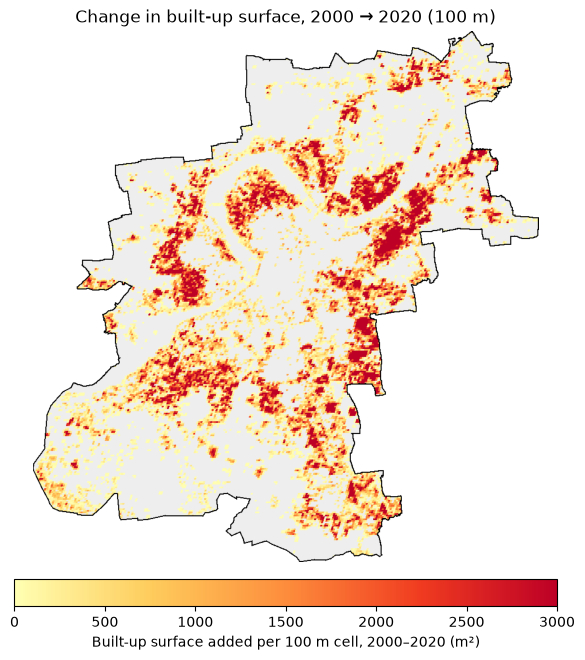

In [11]:
diff_map = city_map(diff.updateMask(diff.gt(0)).visualize(min=0, max=3000, palette=PAL))   # 100 m change map
fig, ax = plt.subplots(figsize=(7, 7.5))
ax.imshow(diff_map); ax.axis("off")
colorbar(fig, ax, PAL, 0, 3000, "Built-up surface added per 100 m cell, 2000–2020 (m²)")
ax.set_title("Change in built-up surface, 2000 → 2020 (100 m)")
fig.savefig(OUT / "fig_change_100m.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
def fishnet(poly, size=1000):
    """Cut a projected polygon into size × size m square cells; edge cells are clipped."""
    x0, y0, x1, y1 = poly.bounds
    cells = [box(x, y, x + size, y + size) for x in np.arange(x0, x1, size) for y in np.arange(y0, y1, size)]
    g = gpd.clip(gpd.GeoDataFrame(geometry=cells, crs=UTM), poly)
    return g[g.geom_type.isin(["Polygon", "MultiPolygon"])].reset_index(drop=True)

city_utm = gdf.to_crs(UTM).geometry.iloc[0]
grid = fishnet(city_utm)
grid["cell_id"] = grid.index
grid["area_ha"] = grid.area / 1e4
print(len(grid), "grid cells")

513 grid cells


In [13]:
cells_ee = geemap.geopandas_to_ee(grid[["cell_id", "geometry"]].to_crs(4326))
rows = stack.reduceRegions(cells_ee, ee.Reducer.sum(), 100, PROJ).getInfo()["features"]   # sum per cell, every epoch
vals = pd.DataFrame([r["properties"] for r in rows]).set_index("cell_id")
vals.index = vals.index.astype(int)
grid = grid.join(vals / 1e4)                       # m² → ha
grid["growth_ha"] = grid.b2020 - grid.b2000

52 hotspot cells (10% of cells) hold 45% of all growth


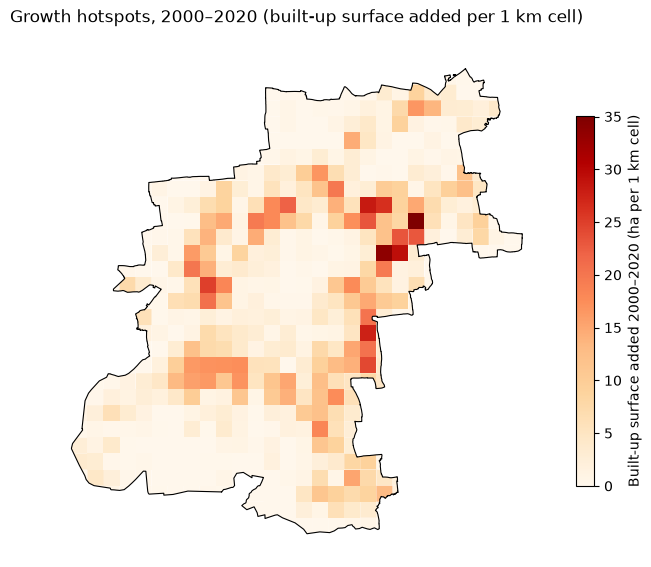

In [14]:
cut = grid.growth_ha.quantile(0.9)                 
hot = grid[grid.growth_ha >= cut]
hot_share = hot.growth_ha.sum() / grid.growth_ha.sum() * 100
print(f"{len(hot)} hotspot cells ({len(hot) / len(grid) * 100:.0f}% of cells) hold {hot_share:.0f}% of all growth")

fig, ax = plt.subplots(figsize=(8, 8))
grid.plot(column="growth_ha", cmap="OrRd", legend=True, ax=ax,
          legend_kwds={"label": "Built-up surface added 2000–2020 (ha per 1 km cell)", "shrink": 0.6})
gpd.GeoSeries([city_utm], crs=UTM).boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("Growth hotspots, 2000–2020 (built-up surface added per 1 km cell)"); ax.axis("off")
fig.savefig(OUT / "fig_hotspots.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Distance from the core: centre or edge?
The **core** is the built-up-weighted centre of Surat in 2000, which is where the 2000 built-up surface is concentrated. It is not simply the middle of the boundary polygon. Every 1 km cell is put in a 2 km distance ring from the core. Two things are measured for each ring:
- the share of land that is built-up in each epoch (the density gradient);
- how much of the city's total growth happened in that ring.

In [15]:
cx, cy = grid.centroid.x, grid.centroid.y
core_x, core_y = np.average(cx, weights=grid.b2000), np.average(cy, weights=grid.b2000)
grid["dist_km"] = np.hypot(cx - core_x, cy - core_y) / 1000
edges = np.arange(0, grid.dist_km.max() + 2, 2)
grid["ring"] = pd.cut(grid.dist_km, edges, labels=[f"{a:.0f}–{a + 2:.0f} km" for a in edges[:-1]])

cols = ["area_ha"] + [f"b{y}" for y in YEARS] + ["growth_ha"]
rings = grid.groupby("ring", observed=True)[cols].sum()
for y in YEARS:
    rings[f"built_pct_{y}"] = rings[f"b{y}"] / rings.area_ha * 100     # share of ring land covered by buildings
rings["share_of_growth_pct"] = rings.growth_ha / rings.growth_ha.sum() * 100
rings[[f"built_pct_{y}" for y in YEARS] + ["growth_ha", "share_of_growth_pct"]].round(1)

,built_pct_2000,built_pct_2005,built_pct_2010,built_pct_2015,built_pct_2020,growth_ha,share_of_growth_pct
ring,,,,,,,
0–2 km,36.2,36.7,37.1,37.5,37.6,19.0,0.9
2–4 km,28.5,29.7,30.9,32.0,32.3,135.8,6.2
4–6 km,18.9,21.4,24.5,27.2,27.7,538.6,24.5
6–8 km,6.2,8.5,11.6,14.3,14.9,634.4,28.9
8–10 km,3.1,4.4,6.1,7.6,8.2,415.8,18.9
10–12 km,3.4,4.0,4.8,5.5,5.9,185.7,8.5
12–14 km,1.7,2.2,2.9,3.5,4.0,152.4,6.9
14–16 km,1.9,2.2,2.7,3.5,5.4,87.8,4.0
16–18 km,2.7,3.3,4.1,4.9,5.6,25.3,1.2


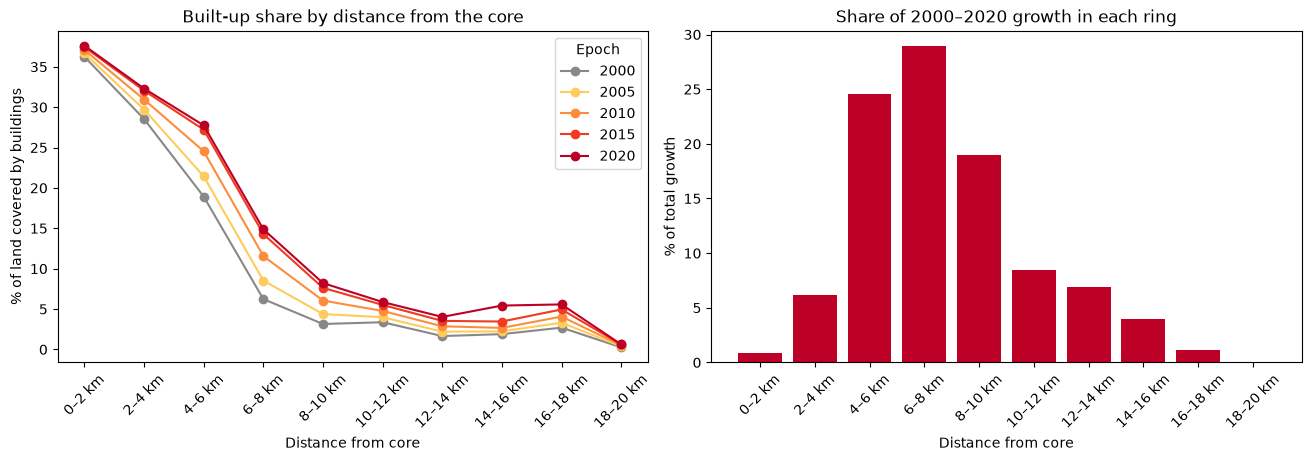

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
for y, c in zip(YEARS, PAL):
    ax1.plot(rings.index.astype(str), rings[f"built_pct_{y}"], "o-", color="#" + c if y != 2000 else "#888888", label=str(y))
ax1.set(title="Built-up share by distance from the core", xlabel="Distance from core", ylabel="% of land covered by buildings")
ax1.legend(title="Epoch"); ax1.tick_params(axis="x", rotation=45)
ax2.bar(rings.index.astype(str), rings.share_of_growth_pct, color="#bd0026")
ax2.set(title="Share of 2000–2020 growth in each ring", xlabel="Distance from core", ylabel="% of total growth")
ax2.tick_params(axis="x", rotation=45)
fig.savefig(OUT / "fig_rings.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Direction: which side of Surat grew most?
Every 1 km cell gets a compass sector (N, NE, … NW) from its bearing to the core. Growth is then summed per sector. **pct_increase** shows how fast each sector grew relative to its own 2000 level.

In [17]:
NAMES = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]
bearing = (np.degrees(np.arctan2(cx - core_x, cy - core_y)) + 360) % 360   # clockwise from north
grid["sector"] = np.array(NAMES)[(((bearing + 22.5) % 360) // 45).astype(int)]

sectors = grid.groupby("sector")[["b2000", "b2020", "growth_ha"]].sum().reindex(NAMES)
sectors["share_of_growth_pct"] = sectors.growth_ha / sectors.growth_ha.sum() * 100
sectors["pct_increase"] = sectors.growth_ha / sectors.b2000 * 100
sectors.sort_values("growth_ha", ascending=False).round(1)

,b2000,b2020,growth_ha,share_of_growth_pct,pct_increase
sector,,,,,
NE,631.2,1235.7,604.5,27.5,95.8
SW,360.8,655.2,294.4,13.4,81.6
S,774.3,1052.6,278.3,12.7,35.9
N,662.4,920.7,258.3,11.8,39.0
NW,516.9,731.7,214.9,9.8,41.6
SE,271.4,483.3,211.9,9.7,78.1
W,369.8,551.7,181.9,8.3,49.2
E,246.3,397.0,150.7,6.9,61.2


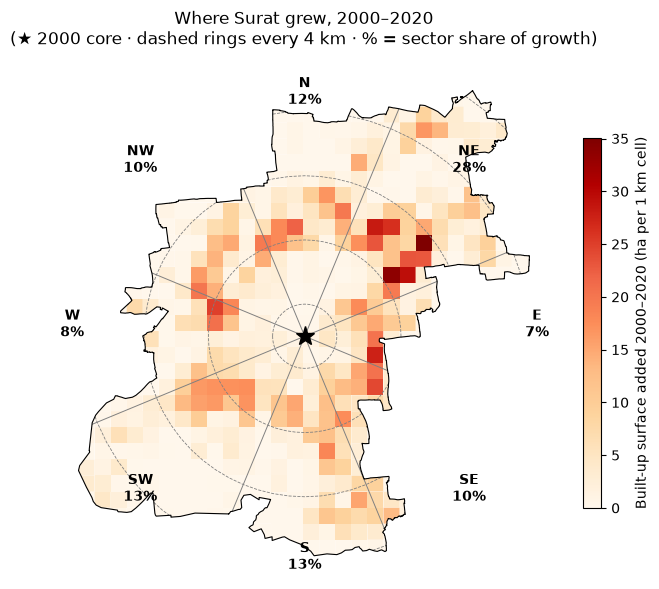

In [18]:
fig, ax = plt.subplots(figsize=(8, 8))
grid.plot(column="growth_ha", cmap="OrRd", ax=ax, legend=True,
          legend_kwds={"label": "Built-up surface added 2000–2020 (ha per 1 km cell)", "shrink": 0.6})
R = grid.dist_km.max() * 1000 + 1000
for i, n in enumerate(NAMES):                      # sector lines and labels
    a = np.radians(i * 45 + 22.5)
    gpd.GeoSeries([LineString([(core_x, core_y), (core_x + R * np.sin(a), core_y + R * np.cos(a))]).intersection(city_utm)], crs=UTM).plot(ax=ax, color="grey", linewidth=0.7)
    b = np.radians(i * 45)
    ax.text(core_x + 0.75 * R * np.sin(b), core_y + 0.75 * R * np.cos(b), f"{n}\n{sectors.loc[n, 'share_of_growth_pct']:.0f}%", ha="center", fontsize=10, weight="bold")
for d in edges[1:-1:2]:                            # every other ring (4, 8, 12 … km) for readability
    gpd.GeoSeries([gpd.points_from_xy([core_x], [core_y])[0].buffer(d * 1000).boundary.intersection(city_utm)], crs=UTM).plot(ax=ax, color="grey", linewidth=0.6, linestyle="--")
ax.plot(core_x, core_y, "k*", markersize=14)
gpd.GeoSeries([city_utm], crs=UTM).boundary.plot(ax=ax, color="black", linewidth=0.8)
ax.set_title("Where Surat grew, 2000–2020\n(★ 2000 core · dashed rings every 4 km · % = sector share of growth)"); ax.axis("off")
fig.savefig(OUT / "fig_where_grew.png", dpi=200, bbox_inches="tight")
plt.show()

## 10. Dynamic outputs
- **Animated GIF:** the five 100 m epoch maps.
- **Interactive time slider:** the 1 km grid on a street basemap. Drag the slider to move through the epochs, and hover a cell to see its numbers. The basemap shows place names, which helps name the growth zones. It is saved as a standalone HTML file for the webpage.

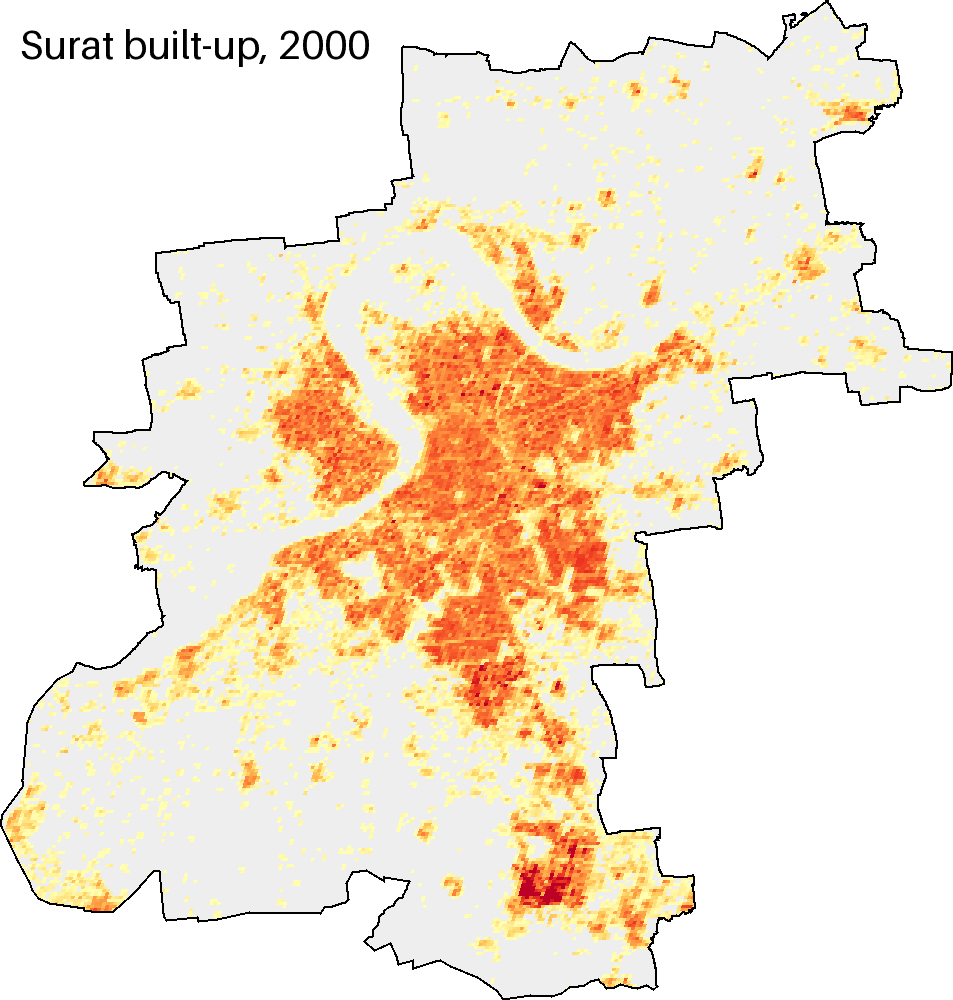

In [19]:
def labelled(arr, text):
    """Write a label on a frame and flatten it onto white for the GIF."""
    bg = Image.new("RGBA", (arr.shape[1], arr.shape[0]), "white")
    bg.alpha_composite(Image.fromarray(arr))
    ImageDraw.Draw(bg).text((20, 20), text, fill="black", font=ImageFont.load_default(size=40))
    return bg.convert("RGB")

gif = [labelled(frames[y], f"Surat built-up, {y}") for y in YEARS]
gif[0].save(OUT / "surat_builtup.gif", save_all=True, append_images=gif[1:], duration=1000, loop=0)
Show(filename=OUT / "surat_builtup.gif")

In [20]:
web = grid.to_crs(4326)[["geometry", "area_ha", "b2000", "b2020", "growth_ha", "sector"]].copy()
web["ring"] = grid.ring.astype(str)
for y in YEARS:
    web[f"pct{y}"] = (grid[f"b{y}"] / grid.area_ha * 100).round(1)   # % of cell covered by buildings
web = web.round(1)
web.to_file(OUT / "surat_grid_1km.geojson", driver="GeoJSON")

vmax = float(np.ceil(web[[f"pct{y}" for y in YEARS]].max().max() / 10) * 10)
cmap = bcm.LinearColormap(["#" + c for c in PAL], vmin=0, vmax=vmax, caption="Share of 1 km cell covered by buildings (%)")
stamp = {y: str(int(pd.Timestamp(f"{y}-01-01").timestamp())) for y in YEARS}
style = {str(i): {stamp[y]: {"color": cmap(r[f"pct{y}"]), "opacity": 0.75} for y in YEARS} for i, r in web.iterrows()}

core_ll = gpd.GeoSeries(gpd.points_from_xy([core_x], [core_y]), crs=UTM).to_crs(4326).iloc[0]
m = folium.Map(location=[core_ll.y, core_ll.x], zoom_start=11, tiles=None)
ESRI = "https://server.arcgisonline.com/ArcGIS/rest/services/{}/MapServer/tile/{{z}}/{{y}}/{{x}}"   # free Esri tiles, no API key
folium.TileLayer(ESRI.format("Canvas/World_Light_Gray_Base"), attr="Tiles © Esri", name="Esri Light Gray").add_to(m)
folium.TileLayer(ESRI.format("World_Imagery"), attr="Tiles © Esri — Maxar, Earthstar Geographics", name="Esri Satellite").add_to(m)
folium.map.CustomPane("labels", z_index=650).add_to(m)      # keeps place names above the grid
folium.TileLayer(ESRI.format("Reference/World_Boundaries_and_Places"), attr="Tiles © Esri", name="Place names",
                 overlay=True, pane="labels").add_to(m)
TimeSliderChoropleth(web.to_json(), styledict=style, name="Built-up share by epoch").add_to(m)
folium.GeoJson(web, name="Cell details", style_function=lambda f: {"fillOpacity": 0, "weight": 0.3, "color": "#666"},
               tooltip=folium.GeoJsonTooltip(fields=["pct2000", "pct2020", "growth_ha", "sector", "ring"],
                                             aliases=["Built % 2000", "Built % 2020", "Added (ha)", "Sector", "Distance"])).add_to(m)
folium.GeoJson(gdf, name="Surat boundary", style_function=lambda f: {"fill": False, "color": "black", "weight": 2}).add_to(m)
folium.Marker([core_ll.y, core_ll.x], tooltip="2000 built-up core").add_to(m)
cmap.add_to(m)
folium.LayerControl().add_to(m)                    # switch gray / satellite, toggle layers
m.save(OUT / "surat_timeslider.html")
m

## 11. Key findings
All the main numbers from sections 3–9 in one place. Use these in the discussion and on the webpage.

In [21]:
fast = df.loc[df.added_km2.idxmax()]
slow = df.loc[df.added_km2.idxmin()]
top = sectors.sort_values("growth_ha", ascending=False)
peak_ring = rings.share_of_growth_pct.idxmax()
findings = [
    f"Built-up surface: {start:.1f} km² (2000) → {end:.1f} km² (2020), +{total_inc:.1f} km² (+{total_pct:.0f}%), {cagr:.1f}% per year.",
    f"Share of the city covered by buildings: {df.pct_of_city.iloc[0]:.1f}% → {df.pct_of_city.iloc[-1]:.1f}%.",
    f"Fastest interval: {int(fast.year) - 5}–{int(fast.year)} (+{fast.added_km2:.1f} km²); slowest: {int(slow.year) - 5}–{int(slow.year)} (+{slow.added_km2:.1f} km²).",
    f"Built-up land (footprint): {df.footprint_km2.iloc[0]:.1f} → {df.footprint_km2.iloc[-1]:.1f} km²; density inside it: {df.density_pct.iloc[0]:.0f}% → {df.density_pct.iloc[-1]:.0f}%.",
    "Gain split: " + "; ".join(f"{k} {v:.0f}%" for k, v in growth.share_pct.items()) + ".",
    f"Hotspots: top 10% of 1 km cells hold {hot_share:.0f}% of all growth.",
    f"Distance: the {peak_ring} ring took the largest share of growth ({rings.share_of_growth_pct.max():.0f}%).",
    f"Direction: {top.index[0]} ({top.share_of_growth_pct.iloc[0]:.0f}%), {top.index[1]} ({top.share_of_growth_pct.iloc[1]:.0f}%) and {top.index[2]} ({top.share_of_growth_pct.iloc[2]:.0f}%) sectors led growth.",
]
print("\n".join("• " + f for f in findings))
df.round(2).to_csv(OUT / "totals.csv", index=False)
rings.round(2).to_csv(OUT / "rings.csv")
sectors.round(2).to_csv(OUT / "sectors.csv")

• Built-up surface: 38.3 km² (2000) → 60.3 km² (2020), +22.0 km² (+57%), 2.3% per year.
• Share of the city covered by buildings: 8.7% → 13.7%.
• Fastest interval: 2005–2010 (+7.2 km²); slowest: 2015–2020 (+2.5 km²).
• Built-up land (footprint): 103.9 → 163.9 km²; density inside it: 37% → 37%.
• Gain split: Densification (built-up in 2000) 22%; Expansion (new built-up land) 71%; Scattered (still sparse in 2020) 7%.
• Hotspots: top 10% of 1 km cells hold 45% of all growth.
• Distance: the 6–8 km ring took the largest share of growth (29%).
• Direction: NE (28%), SW (13%) and S (13%) sectors led growth.


## 12. Discussion

**Spatial pattern:** In 2000 Surat already had a dense core around the bend of the Tapi, and over the next 20 years that core barely changed (0–2 km ring: 36% → 38% covered). Growth went into a ring around it, 4–10 km out, which took 72% of all growth. The north-east led with 28% of growth, and its built-up surface nearly doubled (+96%). Growth was also concentrated rather than spread evenly: the top 10% of 1 km cells hold 45% of the new built-up surface. So the major growth zones are a few clusters, mainly in the north-east and along the eastern and south-western edges of the 2000 footprint.

**Temporal change:** Built-up surface rose from 38.3 km² to 60.3 km² (+22.0 km², +57%), about 2.3% per year. Growth peaked in 2005–10 (+7.2 km²) and slowed sharply in 2015–20 (+2.5 km²). 71% of the gain came from new land becoming built-up, and only 22% from existing areas getting denser. The footprint grew 58% while density inside it stayed around 37%. The pattern is "claim then fill": large footprint additions early, when density dipped to 34%, and smaller additions later, as those areas filled in.

**Limitations**
- **Spatial resolution:** GHSL uses a 100 m grid. Each cell is an estimate of built-up area and does not show individual buildings. Roads and very small plots are not well captured.
- **Temporal resolution:** only 5-year epochs exist, so the exact year of construction is unknown and short bursts of growth are averaged out.
- **Modelled data:** GHSL is derived from satellite imagery plus modelling. Its built-up surface never decreases, so demolition or redevelopment is not captured. The 2020 epoch is the most model-dependent, so the 2015–20 slowdown should be read with caution.
- **Thresholds and zones:** the 10% built-up rule, the 1 km grid, the 2 km rings and the 8 sectors are analytical choices and not official zones. Different choices would shift the numbers somewhat.
- **Boundary:** the SBM municipal boundary is used. Growth just outside it, and recent boundary extensions, are not counted.